<a href="https://colab.research.google.com/github/apiswrld/Tugas-Preprocessing/blob/main/Tugas_Preprocessing_Diabetes_Haffiz_Rizki_R.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Preprocessing Data
## Pima Indians Diabetes Database (data mentah)

**Nama:** Haffiz Rizki Ramadhan  
**NIM:** 2404010008  
**Mata Kuliah:** Data Mining

Notebook ini adalah tahap **preprocessing** untuk tugas klasifikasi risiko diabetes. Data yang dipakai adalah **data asli yang belum dibersihkan** (berkas CSV mentah tanpa header, dengan nilai 0 yang menyamar sebagai data hilang).

**Alur preprocessing:**
1. Memuat data mentah dan memasang nama kolom
2. Inspeksi kualitas data (tipe data, NaN, duplikat, statistik)
3. Menemukan *hidden missing value* (nilai 0 yang tidak masuk akal)
4. Mengubah nilai 0 tersembunyi menjadi `NaN`
5. Mendeteksi outlier dengan metode IQR
6. Membagi data latih dan uji (80:20, stratified), **sebelum** transformasi apa pun
7. Menangani outlier (*capping* IQR), imputasi median, dan standardisasi (semua dipelajari dari data latih saja)
8. Validasi hasil dan menyimpan data bersih

## 1. Import Library

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

sns.set_style("whitegrid")
RANDOM_STATE = 42

## 2. Memuat Data Mentah

Sumber asli: NIDDK, tersedia di [Kaggle](https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database) dan UCI Repository. Berkas CSV mentah yang dipakai sama dengan yang ada di notebook klasifikasi. Berkas ini **tidak punya baris header**, jadi nama kolom dipasang manual sesuai dokumentasi dataset.

Jika unduhan online gagal, unggah berkas `pima-indians-diabetes.data.csv` ke folder kerja lalu jalankan ulang sel ini.

In [ ]:
kolom = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
         "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]

URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
LOKAL = "pima-indians-diabetes.data.csv"

try:
    df_raw = pd.read_csv(URL, header=None, names=kolom)
    print("Data dimuat dari sumber online.")
except Exception as e:
    print("Unduh gagal:", type(e).__name__)
    df_raw = pd.read_csv(LOKAL, header=None, names=kolom)
    print("Data dimuat dari berkas lokal.")

print("Ukuran data (baris, kolom):", df_raw.shape)
df_raw.head(10)

Data dimuat dari sumber online.
Ukuran data (baris, kolom): (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0
8,2,197,70,45,543,30.5,0.158,53,1
9,8,125,96,0,0,0.0,0.232,54,1


## 3. Inspeksi Awal Kualitas Data

In [ ]:
df_raw.info()
print()
print("Missing value (NaN) :", int(df_raw.isnull().sum().sum()))
print("Baris duplikat      :", int(df_raw.duplicated().sum()))
df_raw.describe().T.round(2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Missing value (NaN) : 0
Baris duplikat      : 0


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,768.0,120.89,31.97,0.00,99.00,117.00,140.25,199.00
BloodPressure,768.0,69.11,19.36,0.00,62.00,72.00,80.00,122.00
SkinThickness,768.0,20.54,15.95,0.00,0.00,23.00,32.00,99.00
Insulin,768.0,79.80,115.24,0.00,0.00,30.50,127.25,846.00
BMI,768.0,31.99,7.88,0.00,27.30,32.00,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
Outcome,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


**Temuan awal:** secara teknis data tampak bersih (tidak ada `NaN`, tidak ada duplikat, tipe data numerik semua). Namun nilai **minimum 0** pada `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, dan `BMI` mencurigakan, karena nilai tersebut mustahil secara medis pada manusia hidup.

## 4. Mencari Hidden Missing Value (Nilai 0 Tidak Valid)

`Pregnancies` boleh 0 (belum pernah hamil), dan `Outcome` memang biner 0/1. Lima kolom lainnya tidak boleh bernilai 0.

,Jumlah nilai 0,Persentase (%)
Glucose,5,0.7
BloodPressure,35,4.6
SkinThickness,227,29.6
Insulin,374,48.7
BMI,11,1.4


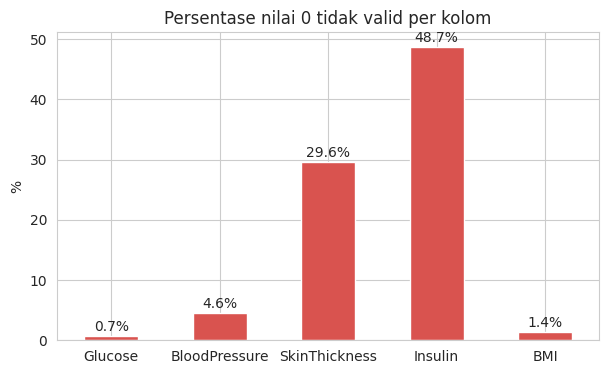

Baris dengan minimal satu nilai 0 tidak valid: 376 dari 768 (49.0%)


In [ ]:
kolom_nol = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

ringkas = pd.DataFrame({
    "Jumlah nilai 0": (df_raw[kolom_nol] == 0).sum(),
    "Persentase (%)": ((df_raw[kolom_nol] == 0).mean() * 100).round(1),
})
display(ringkas)

ax = ringkas["Persentase (%)"].plot(kind="bar", color="#d9534f", figsize=(7, 4))
for i, v in enumerate(ringkas["Persentase (%)"]):
    ax.text(i, v + 0.8, f"{v}%", ha="center")
ax.set_title("Persentase nilai 0 tidak valid per kolom")
ax.set_ylabel("%"); plt.xticks(rotation=0); plt.show()

baris_bermasalah = (df_raw[kolom_nol] == 0).any(axis=1).sum()
print(f"Baris dengan minimal satu nilai 0 tidak valid: {baris_bermasalah} dari {len(df_raw)} "
      f"({baris_bermasalah/len(df_raw)*100:.1f}%)")

**Interpretasi:** `Insulin` (sekitar separuh data) dan `SkinThickness` (sekitar sepertiga data) paling banyak kosong. Karena begitu banyak baris terdampak, **menghapus baris bukan pilihan yang baik** (data hanya 768). Solusinya adalah **imputasi**.

## 5. Mengubah Nilai 0 Tidak Valid menjadi NaN

In [ ]:
df = df_raw.copy()
df[kolom_nol] = df[kolom_nol].replace(0, np.nan)

missing = pd.DataFrame({"Jumlah NaN": df.isnull().sum(),
                        "Persentase (%)": (df.isnull().mean() * 100).round(1)})
missing[missing["Jumlah NaN"] > 0]

,Jumlah NaN,Persentase (%)
Glucose,5,0.7
BloodPressure,35,4.6
SkinThickness,227,29.6
Insulin,374,48.7
BMI,11,1.4


## 6. Deteksi Outlier (Metode IQR)

Batas wajar: `Q1 - 1.5*IQR` sampai `Q3 + 1.5*IQR`. Nilai `NaN` diabaikan dalam perhitungan.

In [ ]:
fitur = [c for c in df.columns if c != "Outcome"]

def hitung_batas(data):
    q1, q3 = data.quantile(0.25), data.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

bawah, atas = hitung_batas(df[fitur])
n_outlier = ((df[fitur] < bawah) | (df[fitur] > atas)).sum()
pd.DataFrame({"Batas bawah": bawah.round(2), "Batas atas": atas.round(2),
              "Jumlah outlier": n_outlier})

,Batas bawah,Batas atas,Jumlah outlier
Pregnancies,-6.50,13.50,4
Glucose,36.00,204.00,0
BloodPressure,40.00,104.00,14
SkinThickness,1.00,57.00,3
Insulin,-94.38,360.62,24
BMI,13.85,50.25,8
DiabetesPedigreeFunction,-0.33,1.20,29
Age,-1.50,66.50,9


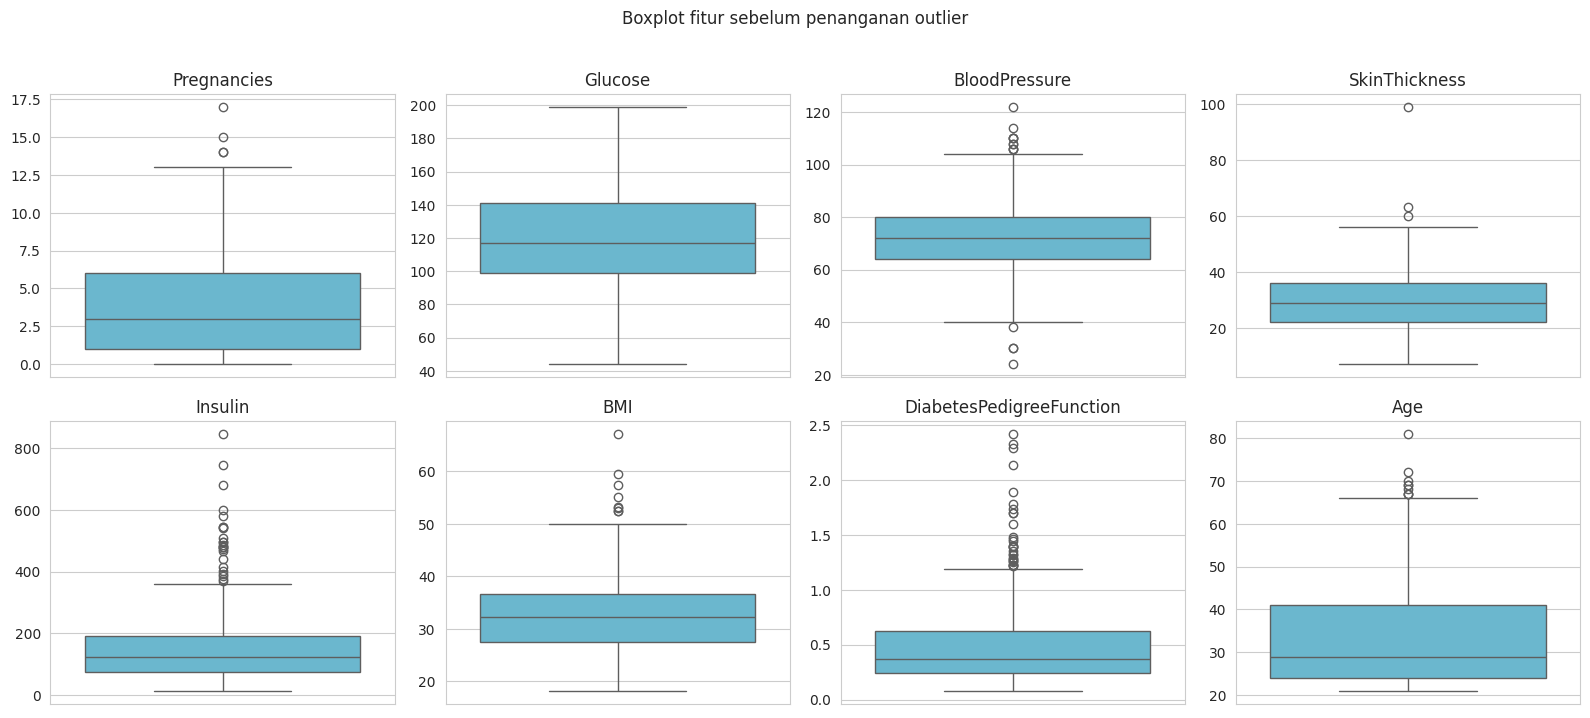

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, f in zip(axes.ravel(), fitur):
    sns.boxplot(y=df[f], ax=ax, color="#5bc0de")
    ax.set_title(f); ax.set_ylabel("")
plt.suptitle("Boxplot fitur sebelum penanganan outlier", y=1.02)
plt.tight_layout(); plt.show()

**Interpretasi:** outlier terbanyak ada di `Insulin` dan `DiabetesPedigreeFunction`. Nilai-nilai ini masih mungkin terjadi secara klinis (bukan salah input), jadi **tidak dihapus**, tetapi dibatasi (*capping*) ke batas IQR agar tidak terlalu memengaruhi model yang sensitif terhadap skala (Logistic Regression, KNN).

## 7. Pembagian Data Latih dan Uji

Pembagian dilakukan **sebelum** capping, imputasi, dan scaling agar tidak terjadi *data leakage*. Memakai `stratify=y` agar proporsi kelas terjaga, dan `random_state=42` agar sama dengan notebook klasifikasi.

In [ ]:
X = df.drop(columns="Outcome")
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)
print("Proporsi diabetes (latih):", round(y_train.mean(), 3), "| (uji):", round(y_test.mean(), 3))

Data latih: (614, 8) | Data uji: (154, 8)
Proporsi diabetes (latih): 0.349 | (uji): 0.351


## 8. Penanganan Outlier, Imputasi, dan Standardisasi

Semua statistik (batas IQR, median, rata-rata, simpangan baku) **dihitung dari data latih saja**, lalu diterapkan ke data uji.

1. **Capping IQR** (`clip`) memakai batas dari data latih
2. **Imputasi median** (tahan terhadap outlier dan sesuai untuk distribusi miring)
3. **Standardisasi** (`StandardScaler`) agar semua fitur berskala sama

In [ ]:
# 1) Capping outlier memakai batas IQR dari data latih
bawah_tr, atas_tr = hitung_batas(X_train)
X_train_cap = X_train.clip(lower=bawah_tr, upper=atas_tr, axis=1)
X_test_cap = X_test.clip(lower=bawah_tr, upper=atas_tr, axis=1)

# 2) Imputasi median (dipelajari dari data latih)
imp = SimpleImputer(strategy="median")
X_train_imp = pd.DataFrame(imp.fit_transform(X_train_cap), columns=fitur, index=X_train.index)
X_test_imp = pd.DataFrame(imp.transform(X_test_cap), columns=fitur, index=X_test.index)

print("Median yang dipakai untuk imputasi (dari data latih):")
print(pd.Series(imp.statistics_, index=fitur).round(2).to_string())

# 3) Standardisasi (dipelajari dari data latih)
scaler = StandardScaler()
X_train_sc = pd.DataFrame(scaler.fit_transform(X_train_imp), columns=fitur, index=X_train.index)
X_test_sc = pd.DataFrame(scaler.transform(X_test_imp), columns=fitur, index=X_test.index)

Median yang dipakai untuk imputasi (dari data latih):
Pregnancies                   3.00
Glucose                     117.00
BloodPressure                72.00
SkinThickness                29.00
Insulin                     125.00
BMI                          32.40
DiabetesPedigreeFunction      0.38
Age                          29.00


## 9. Validasi Hasil Preprocessing

In [ ]:
print("NaN data latih :", int(X_train_sc.isnull().sum().sum()))
print("NaN data uji   :", int(X_test_sc.isnull().sum().sum()))
print("\nRata-rata & std data latih setelah scaling (harus ~0 dan ~1):")
print(X_train_sc.agg(["mean", "std"]).round(3).T.to_string())

print("\nNilai 0 tidak valid tersisa (data sebelum scaling):")
print((X_train_imp[kolom_nol] == 0).sum().sum() + (X_test_imp[kolom_nol] == 0).sum().sum())

NaN data latih : 0
NaN data uji   : 0

Rata-rata & std data latih setelah scaling (harus ~0 dan ~1):
                          mean    std
Pregnancies               -0.0  1.001
Glucose                   -0.0  1.001
BloodPressure             -0.0  1.001
SkinThickness              0.0  1.001
Insulin                    0.0  1.001
BMI                       -0.0  1.001
DiabetesPedigreeFunction  -0.0  1.001
Age                        0.0  1.001

Nilai 0 tidak valid tersisa (data sebelum scaling):
0


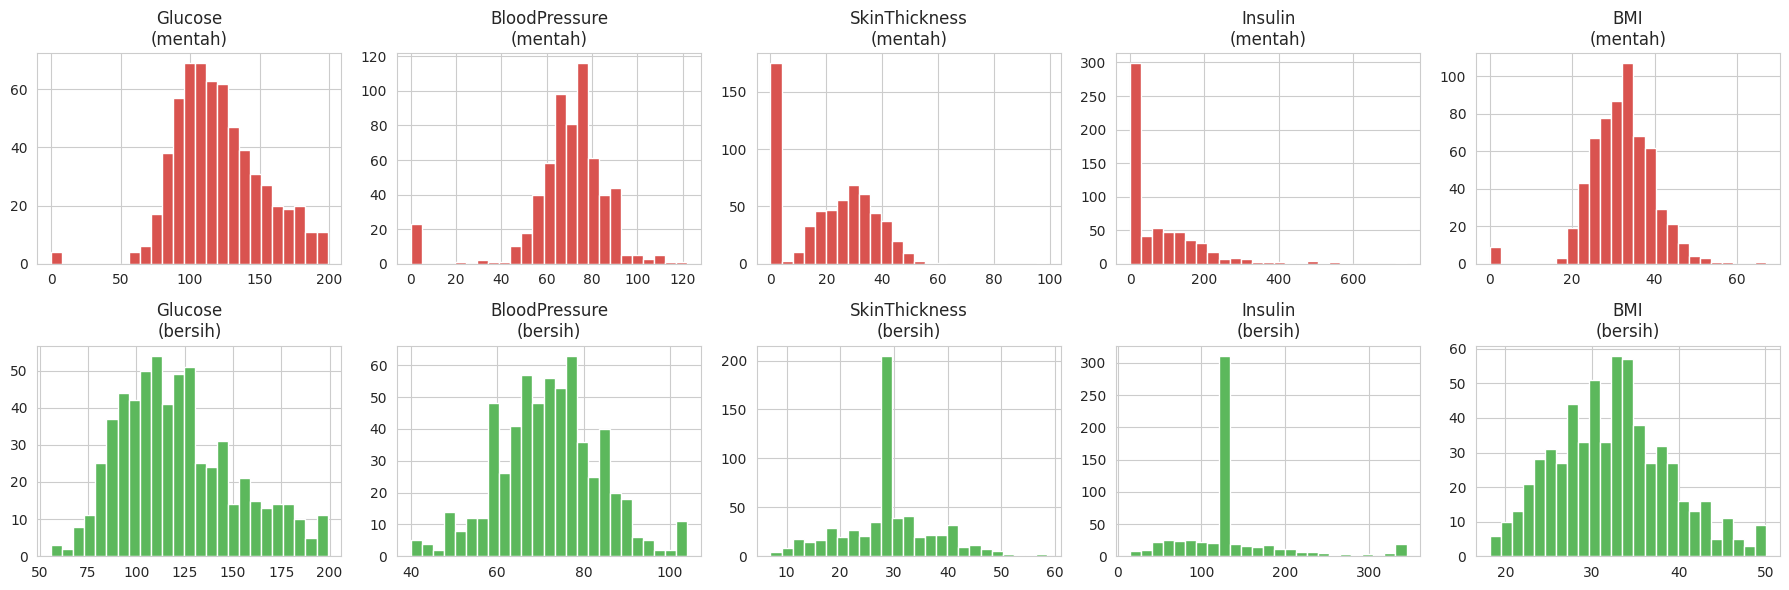

In [ ]:
# Perbandingan distribusi sebelum dan sesudah (data latih)
fig, axes = plt.subplots(2, 5, figsize=(18, 6))
for j, f in enumerate(kolom_nol):
    axes[0, j].hist(df_raw.loc[X_train.index, f], bins=25, color="#d9534f")
    axes[0, j].set_title(f"{f}\n(mentah)")
    axes[1, j].hist(X_train_imp[f], bins=25, color="#5cb85c")
    axes[1, j].set_title(f"{f}\n(bersih)")
plt.tight_layout(); plt.show()

**Interpretasi:** pada data mentah terlihat tumpukan nilai 0 di sisi kiri tiap histogram. Setelah preprocessing, tumpukan tersebut hilang dan distribusi kembali masuk akal.

## 10. Menyimpan Hasil

In [ ]:
os.makedirs("hasil_preprocessing", exist_ok=True)

# Data mentah + header
df_raw.to_csv("hasil_preprocessing/pima_diabetes_mentah.csv", index=False)

# Data bersih (sudah capping & imputasi, belum di-scaling) -> mudah dibaca/ditafsirkan
bersih = pd.concat([X_train_imp.assign(Outcome=y_train, Set="train"),
                    X_test_imp.assign(Outcome=y_test, Set="test")]).sort_index()
bersih.to_csv("hasil_preprocessing/pima_diabetes_bersih.csv", index=False)

# Data siap model (ter-scaling), dipisah latih dan uji
X_train_sc.assign(Outcome=y_train).to_csv("hasil_preprocessing/train_siap_model.csv", index=False)
X_test_sc.assign(Outcome=y_test).to_csv("hasil_preprocessing/test_siap_model.csv", index=False)

print(os.listdir("hasil_preprocessing"))
bersih.head()

['train_siap_model.csv', 'pima_diabetes_bersih.csv', 'pima_diabetes_mentah.csv', 'test_siap_model.csv']


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,Set
0,6.0,148.0,72.0,35.0,125.0,33.6,0.627000,50.0,1,train
1,1.0,85.0,66.0,29.0,125.0,26.6,0.351000,31.0,0,train
2,8.0,183.0,64.0,29.0,125.0,23.3,0.672000,32.0,1,train
3,1.0,89.0,66.0,23.0,94.0,28.1,0.167000,21.0,0,test
4,0.0,137.0,40.0,35.0,168.0,43.1,1.230625,33.0,1,train


## 11. Ringkasan

| Masalah pada data mentah | Penanganan |
|---|---|
| Tidak ada header | Nama kolom dipasang manual sesuai dokumentasi |
| Nilai 0 tidak valid (hidden missing) pada 5 kolom | Diubah menjadi `NaN` |
| `NaN` banyak (Insulin ~49%, SkinThickness ~30%) | Imputasi median dari data latih |
| Outlier (terutama Insulin, DPF) | *Capping* IQR dari data latih |
| Skala fitur berbeda jauh | `StandardScaler` dari data latih |
| Risiko data leakage | Split dulu, semua statistik hanya dari data latih |
| Kelas tidak seimbang (~65:35) | `stratify=y` saat split |

Data hasil preprocessing siap dipakai untuk tahap pemodelan klasifikasi.